# DDPM（2020）二维双峰实验：前向扩散、噪声预测与反向生成

这个 notebook 用一个具有解析密度的二维双峰高斯分布，完整实现 Ho et al.（2020）的 DDPM 核心流程。二维实验可以直接观察每个中间分布，也能把网络预测的噪声换算成 Score 后与解析答案比较。

实验将验证：

1. 固定的前向过程如何把数据逐渐变成标准高斯；
2. 如何用闭式公式一步采样任意 $x_t$，而不必真的执行 $t$ 次加噪；
3. 噪声预测 MSE 如何训练 $\epsilon_\theta(x_t,t)$；
4. 如何用网络参数化反向高斯均值并逐步生成数据；
5. 噪声预测与 Score 估计为什么等价。

> 运行环境：`conda activate pytorch`。本 notebook 固定随机种子，一次“全部运行”即可复现结果。

## 1. 数据分布与实验配置

真实分布为等权二维高斯混合：

$$
q_{\mathrm{data}}(x)=\tfrac12\mathcal N((-3,0),0.3^2I)
+\tfrac12\mathcal N((3,0),0.3^2I).
$$

我们使用论文中的 1000 个扩散步和线性 $\beta_t$ 调度。原始草稿使用 $T=200$，对应 $\bar\alpha_T\approx0.132$，数据在终点仍保留明显信号，不适合直接令 $p(x_T)=\mathcal N(0,I)$。这里使用 $T=1000$ 后 $\bar\alpha_T\approx4\times10^{-5}$，终点近似标准高斯。

In [1]:
from pathlib import Path
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

OUTPUT_DIR = Path("ddpm_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

DIM = 2
CENTERS = torch.tensor([[-3.0, 0.0], [3.0, 0.0]], device=DEVICE)
DATA_STD = 0.3
MIXTURE_WEIGHTS = torch.tensor([0.5, 0.5], device=DEVICE)

T = 1_000
BATCH_SIZE = 1_024
TRAIN_STEPS = 8_000
LEARNING_RATE = 1e-3
N_SAMPLES = 3_000

print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

PyTorch: 2.5.1
Device: cuda
Output directory: /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/ddpm_outputs


In [2]:
def sample_data(n):
    labels = torch.randint(0, 2, (n,), device=DEVICE)
    return CENTERS[labels] + DATA_STD * torch.randn(n, DIM, device=DEVICE)


with torch.no_grad():
    data_check = sample_data(20_000)
    assignment = torch.cdist(data_check, CENTERS).argmin(dim=1)
    empirical_weights = torch.bincount(assignment, minlength=2).float() / len(data_check)

print("Empirical weights:", empirical_weights.cpu().numpy().round(3))
print("Empirical mean:", data_check.mean(0).cpu().numpy().round(3))
print("Empirical std:", data_check.std(0).cpu().numpy().round(3))

Empirical weights: [0.497 0.503]
Empirical mean: [0.017 0.002]
Empirical std: [3.017 0.299]


## 2. 前向扩散的噪声调度

单步前向转移定义为

$$
q(x_t\mid x_{t-1})=\mathcal N(\sqrt{\alpha_t}x_{t-1},\beta_tI),
\qquad \alpha_t=1-\beta_t.
$$

记 $\bar\alpha_t=\prod_{s=1}^t\alpha_s$，利用高斯分布的可重参数化，可以直接从 $x_0$ 跳到任意时间：

$$
x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon,
\qquad\epsilon\sim\mathcal N(0,I).
$$

代码采用 0-based 下标：数组位置 `t=0,...,999` 对应论文时间 $t=1,...,1000$。

In [3]:
betas = torch.linspace(1e-4, 0.02, T, device=DEVICE)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
alpha_bars_prev = torch.cat([torch.ones(1, device=DEVICE), alpha_bars[:-1]])

# q(x_{t-1} | x_t, x_0) 的方差，也称 beta_tilde。
posterior_variance = betas * (1.0 - alpha_bars_prev) / (1.0 - alpha_bars)
posterior_variance[0] = 0.0


def extract(values, t, x_shape):
    # 从长度为 T 的表中取出 batch 对应项，并扩展成可广播形状。
    return values.gather(0, t).reshape(t.shape[0], *((1,) * (len(x_shape) - 1)))


def q_sample(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)
    alpha_bar = extract(alpha_bars, t, x0.shape)
    return torch.sqrt(alpha_bar) * x0 + torch.sqrt(1.0 - alpha_bar) * noise


print(f"alpha_bar_T = {alpha_bars[-1].item():.8f}")
print(f"sqrt(alpha_bar_T) = {alpha_bars[-1].sqrt().item():.6f}")
print(f"terminal noise std = {(1-alpha_bars[-1]).sqrt().item():.6f}")

alpha_bar_T = 0.00004036
sqrt(alpha_bar_T) = 0.006353
terminal noise std = 0.999980


## 3. 可视化前向扩散

下图复用同一批 $x_0$，在不同时间独立抽取噪声。随着信噪比

$$
\mathrm{SNR}(t)=\frac{\bar\alpha_t}{1-\bar\alpha_t}
$$

下降，两个模态逐渐重合；终点的均值和方差都接近标准高斯。

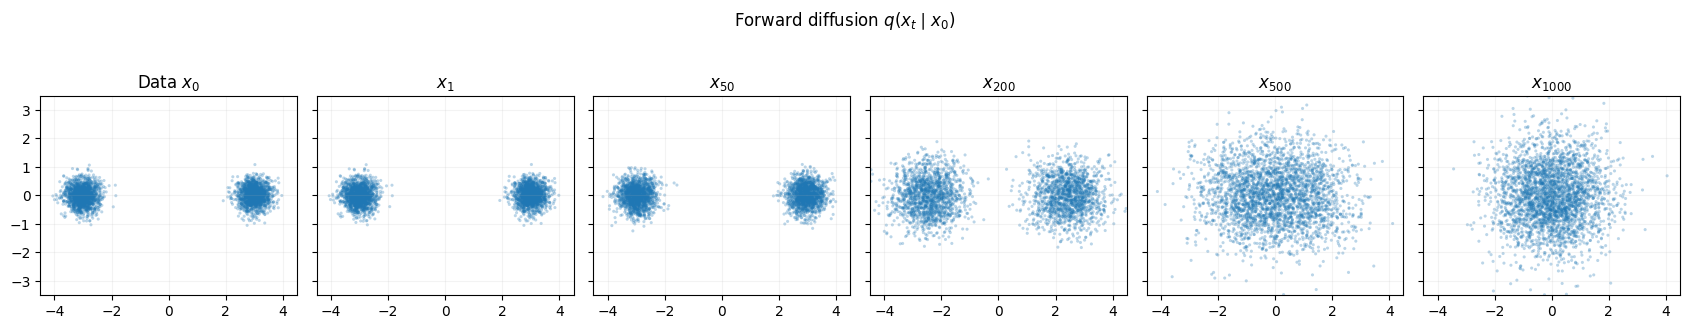

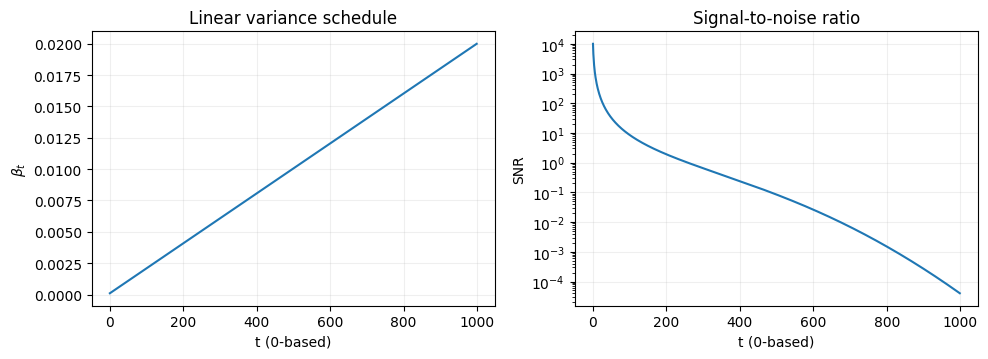

In [4]:
@torch.no_grad()
def plot_forward_process():
    x0 = sample_data(N_SAMPLES)
    display_steps = [0, 49, 199, 499, 999]
    fig, axes = plt.subplots(1, 6, figsize=(17, 3.1), sharex=True, sharey=True)

    arrays = [x0.cpu().numpy()]
    titles = ["Data $x_0$"]
    for t_value in display_steps:
        t_batch = torch.full((N_SAMPLES,), t_value, device=DEVICE, dtype=torch.long)
        arrays.append(q_sample(x0, t_batch).cpu().numpy())
        titles.append(f"$x_{{{t_value+1}}}$")

    for ax, points, title in zip(axes, arrays, titles):
        ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.3, edgecolors="none")
        ax.set_title(title)
        ax.set_xlim(-4.5, 4.5)
        ax.set_ylim(-3.5, 3.5)
        ax.set_aspect("equal")
        ax.grid(alpha=0.15)
    fig.suptitle("Forward diffusion $q(x_t\\mid x_0)$", y=1.04)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "01_forward_diffusion.png", dpi=160, bbox_inches="tight")
    plt.show()

    snr = alpha_bars / (1.0 - alpha_bars)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
    axes[0].plot(betas.cpu())
    axes[0].set(xlabel="t (0-based)", ylabel=r"$\beta_t$", title="Linear variance schedule")
    axes[1].semilogy(snr.cpu())
    axes[1].set(xlabel="t (0-based)", ylabel="SNR", title="Signal-to-noise ratio")
    for ax in axes:
        ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "02_schedule_and_snr.png", dpi=160, bbox_inches="tight")
    plt.show()


plot_forward_process()

## 4. 噪声预测网络 $\epsilon_\theta(x_t,t)$

网络接收二维坐标和正弦时间编码。时间编码使同一个 MLP 能区分不同噪声尺度。图像 DDPM 通常使用带时间条件的 U-Net；这里将空间网络换成 MLP，其余概率过程保持一致。

In [5]:
class NoisePredictor(nn.Module):
    def __init__(self, hidden_dim=128, time_dim=64):
        super().__init__()
        self.time_dim = time_dim
        self.net = nn.Sequential(
            nn.Linear(DIM + time_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, DIM),
        )

    def time_embedding(self, t):
        half = self.time_dim // 2
        frequencies = torch.exp(
            -math.log(10_000) * torch.arange(half, device=t.device) / max(half - 1, 1)
        )
        angles = t.float()[:, None] * frequencies[None, :]
        return torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)

    def forward(self, x, t):
        return self.net(torch.cat([x, self.time_embedding(t)], dim=1))


model = NoisePredictor().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

NoisePredictor(
  (net): Sequential(
    (0): Linear(in_features=66, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
)
Trainable parameters: 41,858


## 5. 简化训练目标 $L_{\mathrm{simple}}$

每次训练只需：采样 $x_0$、均匀采样时间 $t$、采样 $\epsilon$、闭式构造 $x_t$，然后最小化

$$
L_{\mathrm{simple}}=
\mathbb E_{t,x_0,\epsilon}
\left[\|\epsilon-\epsilon_\theta(x_t,t)\|_2^2\right].
$$

这个目标来自 ELBO 中高斯 KL 项的重参数化。严格 ELBO 会给不同时间步不同权重；论文发现去掉该权重的简化目标能改善样本质量。它优化的是重新加权后的去噪目标，因此不能直接当作完整负 ELBO 的数值。

In [6]:
losses = []
model.train()
started = time.perf_counter()

for step in range(1, TRAIN_STEPS + 1):
    x0 = sample_data(BATCH_SIZE)
    t = torch.randint(0, T, (BATCH_SIZE,), device=DEVICE)
    noise = torch.randn_like(x0)
    xt = q_sample(x0, t, noise)
    predicted_noise = model(xt, t)
    loss = (noise - predicted_noise).square().mean()

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

    if step == 1 or step % 800 == 0:
        print(f"step {step:4d}/{TRAIN_STEPS} | loss(200-step avg)={np.mean(losses[-200:]):.6f}")

print(f"Training finished in {time.perf_counter() - started:.1f} s")
torch.save(model.state_dict(), OUTPUT_DIR / "ddpm_2d_state_dict.pt")

step    1/8000 | loss(200-step avg)=0.992480


step  800/8000 | loss(200-step avg)=0.185119


step 1600/8000 | loss(200-step avg)=0.184310


step 2400/8000 | loss(200-step avg)=0.182108


step 3200/8000 | loss(200-step avg)=0.180574


...

step 4800/8000 | loss(200-step avg)=0.180182


step 5600/8000 | loss(200-step avg)=0.181666


step 6400/8000 | loss(200-step avg)=0.181483


step 7200/8000 | loss(200-step avg)=0.180757


step 8000/8000 | loss(200-step avg)=0.182768
Training finished in 34.8 s


## 6. 解析 Score 与独立验证

前向过程作用在高斯混合上仍得到高斯混合。第 $i$ 个分量在时刻 $t$ 的均值与方差为

$$
m_{i,t}=\sqrt{\bar\alpha_t}\mu_i,\qquad
v_t=\bar\alpha_t\,0.3^2+(1-\bar\alpha_t).
$$

因此可以解析计算 $\nabla_{x_t}\log q_t(x_t)$。噪声预测和 Score 的关系是

$$
s_\theta(x_t,t)=-\frac{\epsilon_\theta(x_t,t)}{\sqrt{1-\bar\alpha_t}}.
$$

训练 loss 含有不可约的条件噪声，不应期望降到零；与解析 Score 的独立误差更能判断网络是否学对。

 paper t    alpha_bar      score MSE     scaled MSE
      10     0.998105       1.665380       0.003156
      50     0.971016       0.170818       0.004951
     200     0.659039       0.014592       0.004975
     500     0.078587       0.000976       0.000899
     800     0.001532       0.000755       0.000754
    1000     0.000040       0.000920       0.000920


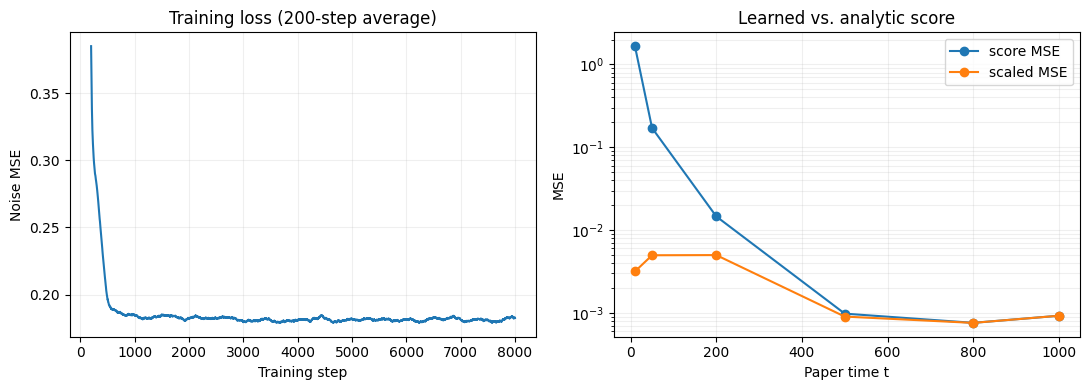

In [7]:
def true_score(xt, t_value):
    alpha_bar = alpha_bars[t_value]
    means_t = torch.sqrt(alpha_bar) * CENTERS
    variance_t = alpha_bar * DATA_STD**2 + (1.0 - alpha_bar)
    diff = xt[:, None, :] - means_t[None, :, :]
    log_prob = torch.log(MIXTURE_WEIGHTS)[None, :] - diff.square().sum(-1) / (2 * variance_t)
    responsibilities = torch.softmax(log_prob, dim=1)
    return (responsibilities[:, :, None] * (-diff / variance_t)).sum(dim=1)


@torch.no_grad()
def learned_score(xt, t_value):
    t_batch = torch.full((len(xt),), t_value, device=DEVICE, dtype=torch.long)
    return -model(xt, t_batch) / torch.sqrt(1.0 - alpha_bars[t_value])


@torch.no_grad()
def evaluate_model(n=10_000):
    model.eval()
    test_times = [9, 49, 199, 499, 799, 999]
    rows = []
    for t_value in test_times:
        x0 = sample_data(n)
        t_batch = torch.full((n,), t_value, device=DEVICE, dtype=torch.long)
        xt = q_sample(x0, t_batch)
        pred = learned_score(xt, t_value)
        target = true_score(xt, t_value)
        mse = (pred - target).square().mean().item()
        scaled_mse = ((1-alpha_bars[t_value]) * (pred-target).square()).mean().item()
        rows.append((t_value + 1, alpha_bars[t_value].item(), mse, scaled_mse))
    return np.asarray(rows)


score_metrics = evaluate_model()
print(f"{'paper t':>8} {'alpha_bar':>12} {'score MSE':>14} {'scaled MSE':>14}")
for paper_t, alpha_bar, mse, scaled_mse in score_metrics:
    print(f"{int(paper_t):8d} {alpha_bar:12.6f} {mse:14.6f} {scaled_mse:14.6f}")

window = 200
loss_smooth = np.convolve(losses, np.ones(window) / window, mode="valid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.arange(window, len(losses)+1), loss_smooth)
axes[0].set(xlabel="Training step", ylabel="Noise MSE", title=f"Training loss ({window}-step average)")
axes[0].grid(alpha=0.2)
axes[1].semilogy(score_metrics[:, 0], score_metrics[:, 2], "o-", label="score MSE")
axes[1].semilogy(score_metrics[:, 0], score_metrics[:, 3], "o-", label="scaled MSE")
axes[1].set(xlabel="Paper time t", ylabel="MSE", title="Learned vs. analytic score")
axes[1].legend()
axes[1].grid(alpha=0.2, which="both")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_training_and_score_error.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. 可视化 Score 场

选择较早的 $t=200$，此时两个模态仍然可辨。解析场和学习场都应把空间中的点推向高密度区域；两个模态之间存在分界结构。背景颜色表示 Score 长度，箭头表示方向。

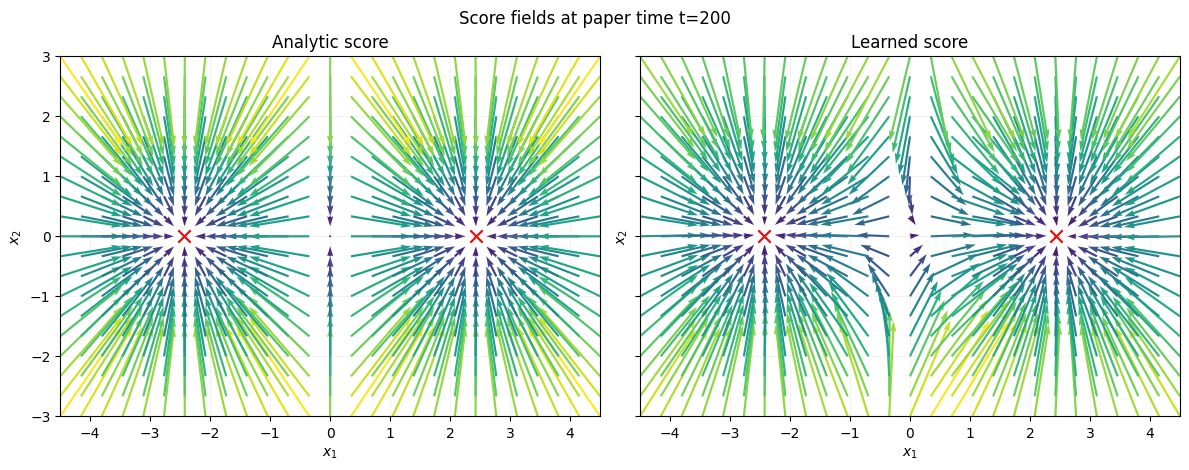

In [8]:
@torch.no_grad()
def plot_score_fields(t_value=199):
    xs = torch.linspace(-4.5, 4.5, 27, device=DEVICE)
    ys = torch.linspace(-3.0, 3.0, 19, device=DEVICE)
    yy, xx = torch.meshgrid(ys, xs, indexing="ij")
    points = torch.stack([xx.ravel(), yy.ravel()], dim=1)
    fields = [true_score(points, t_value), learned_score(points, t_value)]
    titles = ["Analytic score", "Learned score"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
    p = points.cpu().numpy()
    for ax, field, title in zip(axes, fields, titles):
        f = field.cpu().numpy()
        magnitude = np.linalg.norm(f, axis=1)
        ax.quiver(p[:, 0], p[:, 1], f[:, 0], f[:, 1], magnitude,
                  cmap="viridis", angles="xy", scale_units="xy", scale=5.0, width=0.004)
        current_centers = (alpha_bars[t_value].sqrt() * CENTERS).cpu().numpy()
        ax.scatter(current_centers[:, 0], current_centers[:, 1], c="red", marker="x", s=80)
        ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", xlim=(-4.5, 4.5), ylim=(-3, 3))
        ax.set_aspect("equal")
        ax.grid(alpha=0.15)
    fig.suptitle(f"Score fields at paper time t={t_value+1}")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "04_score_fields.png", dpi=160, bbox_inches="tight")
    plt.show()


plot_score_fields()

## 8. 反向扩散采样

用预测噪声参数化反向均值：

$$
\mu_\theta(x_t,t)=\frac{1}{\sqrt{\alpha_t}}
\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}
\epsilon_\theta(x_t,t)\right).
$$

随后采样

$$
x_{t-1}=\mu_\theta(x_t,t)+\sqrt{\tilde\beta_t}z,
$$

其中 $\tilde\beta_t=\beta_t(1-\bar\alpha_{t-1})/(1-\bar\alpha_t)$。在最后一步令噪声为零。这里采用论文的 fixed-small 后验方差选择。

In [9]:
@torch.no_grad()
def p_sample(xt, t_value):
    t_batch = torch.full((len(xt),), t_value, device=DEVICE, dtype=torch.long)
    predicted_noise = model(xt, t_batch)
    mean = (
        xt - betas[t_value] / torch.sqrt(1.0-alpha_bars[t_value]) * predicted_noise
    ) / torch.sqrt(alphas[t_value])
    if t_value == 0:
        return mean
    return mean + torch.sqrt(posterior_variance[t_value]) * torch.randn_like(xt)


@torch.no_grad()
def sample_reverse(n=N_SAMPLES):
    model.eval()
    x = torch.randn(n, DIM, device=DEVICE)
    keep_after_steps = {1000, 800, 500, 200, 1}
    snapshots = {1000: x.cpu().numpy().copy()}

    for t_value in reversed(range(T)):
        x = p_sample(x, t_value)
        remaining = t_value
        if remaining in {800, 500, 200, 0}:
            snapshots[remaining] = x.cpu().numpy().copy()
    return x.cpu().numpy(), snapshots


sampling_started = time.perf_counter()
generated, reverse_snapshots = sample_reverse()
print(f"Reverse sampling finished in {time.perf_counter()-sampling_started:.1f} s")

Reverse sampling finished in 1.8 s


## 9. 反向轨迹与生成结果

轨迹图从 $x_T\sim\mathcal N(0,I)$ 开始。时间下降时，单峰先沿横轴展开，再分裂成两个窄模态。最终用最近中心分配样本，并检查两个分量的比例、分量均值和分量内标准差。

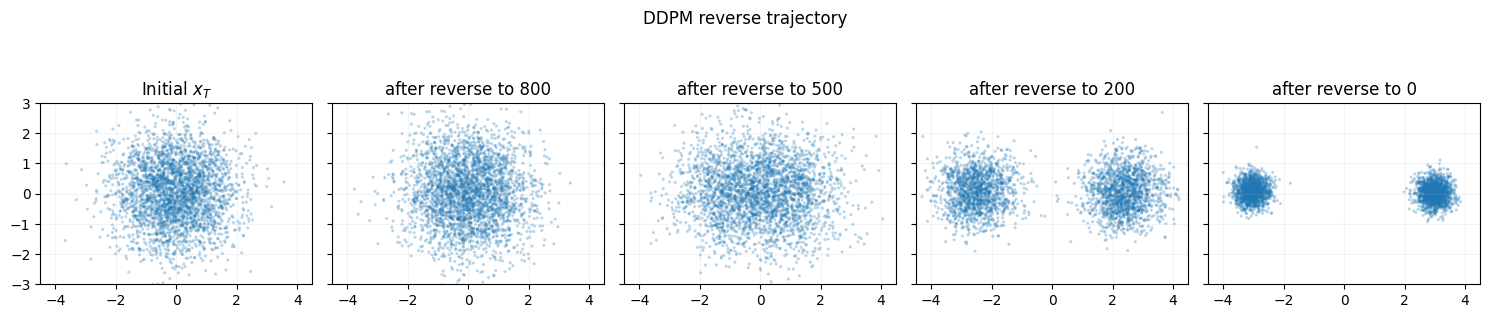

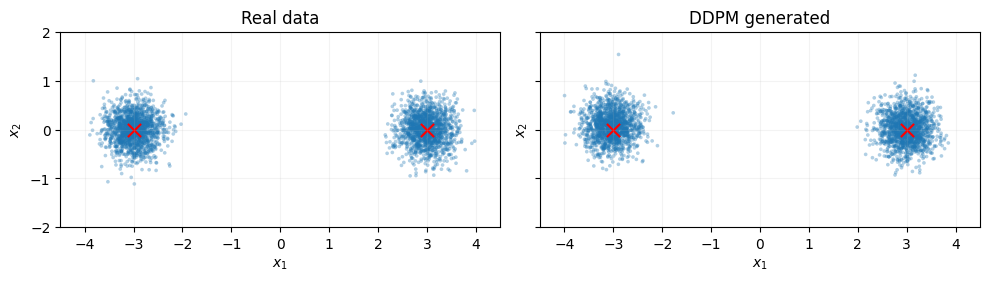

Target weights:    [0.5 0.5]
Generated weights: [0.49 0.51]
Target centers:
 [[-3.  0.]
 [ 3.  0.]]
Generated component means:
 [[-3.03   0.075]
 [ 2.996  0.011]]
Target within-component std: 0.3
Generated component stds:
 [[0.293 0.296]
 [0.291 0.301]]


In [10]:
keys = [1000, 800, 500, 200, 0]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.1), sharex=True, sharey=True)
for ax, key in zip(axes, keys):
    points = reverse_snapshots[key]
    ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.3, edgecolors="none")
    ax.set_title("Initial $x_T$" if key == 1000 else f"after reverse to {key}")
    ax.set_xlim(-4.5, 4.5)
    ax.set_ylim(-3.0, 3.0)
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)
fig.suptitle("DDPM reverse trajectory", y=1.04)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "05_reverse_trajectory.png", dpi=160, bbox_inches="tight")
plt.show()

with torch.no_grad():
    real = sample_data(N_SAMPLES).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), sharex=True, sharey=True)
for ax, points, title in zip(axes, [real, generated], ["Real data", "DDPM generated"]):
    ax.scatter(points[:, 0], points[:, 1], s=7, alpha=0.35, edgecolors="none")
    ax.scatter(CENTERS[:, 0].cpu(), CENTERS[:, 1].cpu(), c="red", marker="x", s=90)
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", xlim=(-4.5, 4.5), ylim=(-2, 2))
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_generated_vs_real.png", dpi=160, bbox_inches="tight")
plt.show()


def component_summary(points):
    points_t = torch.as_tensor(points, dtype=torch.float32, device=DEVICE)
    labels = torch.cdist(points_t, CENTERS).argmin(dim=1)
    weights = torch.bincount(labels, minlength=2).float() / len(points_t)
    means = torch.stack([points_t[labels == i].mean(0) for i in range(2)])
    stds = torch.stack([points_t[labels == i].std(0) for i in range(2)])
    return weights.cpu().numpy(), means.cpu().numpy(), stds.cpu().numpy()


real_weights, real_means, real_stds = component_summary(real)
gen_weights, gen_means, gen_stds = component_summary(generated)
print("Target weights:   ", MIXTURE_WEIGHTS.cpu().numpy())
print("Generated weights:", np.round(gen_weights, 3))
print("Target centers:\n", CENTERS.cpu().numpy())
print("Generated component means:\n", np.round(gen_means, 3))
print("Target within-component std:", DATA_STD)
print("Generated component stds:\n", np.round(gen_stds, 3))

## 10. 代码与论文公式的对应关系

| Notebook 对象 | 数学对象 | 作用 |
|---|---|---|
| `betas` | $\beta_t$ | 每一步加入的噪声方差 |
| `alphas` | $\alpha_t=1-\beta_t$ | 单步信号保留比例 |
| `alpha_bars` | $\bar\alpha_t=\prod_{s=1}^t\alpha_s$ | 累积信号保留比例 |
| `q_sample()` | $q(x_t\mid x_0)$ | 闭式采样任意前向时刻 |
| `posterior_variance` | $\tilde\beta_t$ | 前向后验及反向模型固定方差 |
| `NoisePredictor` | $\epsilon_\theta(x_t,t)$ | 预测前向过程中加入的噪声 |
| 训练循环 | $L_{\mathrm{simple}}$ | 简化噪声 MSE 目标 |
| `p_sample()` | $p_\theta(x_{t-1}\mid x_t)$ | 一步反向高斯采样 |
| `learned_score()` | $-\epsilon_\theta/\sqrt{1-\bar\alpha_t}$ | 从噪声预测恢复 Score |

### 最重要的结论

网络预测噪声是参数化反向均值的一种方式。完整生成链是

$$
x_0\xrightarrow{q\ \text{固定加噪}}x_T,
\qquad
x_T\sim\mathcal N(0,I)
\xrightarrow{p_\theta\ \text{逐步去噪}}x_0.
$$

检查实验是否成功时，不能只看训练 loss。还应同时确认：$\bar\alpha_T$ 足够小、学习 Score 接近解析 Score、反向轨迹逐渐分裂为两个模态，以及生成分量的中心、标准差和权重接近真实分布。